<a href="https://colab.research.google.com/github/p2ms/Predicao-de-baterias-universitarias-/blob/main/Modelo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Pipeline pós Coleta

In [ ]:
import pandas as pd, numpy as np
pd.set_option("display.width", 200)

df_tor = pd.read_csv("resultados_por_torneio.csv")
df_bat = pd.read_csv("participacoes_por_bateria.csv")

print(df_tor.shape, df_tor.columns.tolist())
display(df_tor.head(10))
print(df_bat.shape, df_bat.columns.tolist())
display(df_bat.head(5))

(3140, 12) ['torneio_slug', 'pagina', 'Ano', 'Campeã', 'Pontuação', 'Estandartes', 'link', '#', 'Bateria', 'Pts', 'Arquivos', 'Divisão']


,torneio_slug,pagina,Ano,Campeã,Pontuação,Estandartes,link,#,Bateria,Pts,Arquivos,Divisão
0,aue,/torneios/aue,2026.0,FuriosaUTFPR-CP,97.79,CaixaChocalhoMestreRepiqueSurdo de MarcaçãoTam...,/torneios/aue/2026,NaN,NaN,NaN,NaN,NaN
1,aue,/torneios/aue,2025.0,RapoZona,97.60,AgogôChocalhoMestreRepiqueSurdo de Marcação,/torneios/aue/2025,NaN,NaN,NaN,NaN,NaN
2,aue,/torneios/aue,2024.0,RapoZona,96.12,AgogôRepique,/torneios/aue/2024,NaN,NaN,NaN,NaN,NaN
3,aue,/torneios/aue,2023.0,RapoZona,96.15,Diferenciado (Triângulo)Repique,/torneios/aue/2023,NaN,NaN,NaN,NaN,NaN
4,2023,/torneios/aue/2023,NaN,NaN,NaN,Diferenciado (Triângulo)Repique,/baterias/rapozona,1,RapoZona,96.15,NaN,NaN
5,2023,/torneios/aue/2023,NaN,NaN,NaN,AgogôMestreSurdo de MarcaçãoSurdo de Terceira,/baterias/homunculoco,2,Homunculoco,94.17,NaN,NaN
6,2023,/torneios/aue/2023,NaN,NaN,NaN,CaixaTamborim,/baterias/os-coringas,3,Os Coringas,93.75,NaN,NaN
7,2023,/torneios/aue/2023,NaN,NaN,NaN,Chocalho,/baterias/caveirao,4,Caveirão,91.82,NaN,NaN
8,2023,/torneios/aue/2023,NaN,NaN,NaN,—,/baterias/imortal-uepg,5,ImortalUEPG,90.70,NaN,NaN
9,2023,/torneios/aue/2023,NaN,NaN,NaN,—,/baterias/lolloteria,6,LolloteriaUEL,90.52,NaN,NaN


(2715, 8) ['bateria_slug', 'pagina', 'Torneio', '#', 'Pts', 'Estandartes', 'Arquivos', 'link']


,bateria_slug,pagina,Torneio,#,Pts,Estandartes,Arquivos,link
0,aaatucada,/baterias/aaatucada,TABU2016,9,105.80,—,NaN,/torneios/tabu/2016
1,abissal,/baterias/abissal,InterMed Nordeste2025,9,40.84,Complementar,NaN,/torneios/intermed-nordeste/2025
2,abissal,/baterias/abissal,InterMed Nordeste2024,8,40.59,—,NaN,/torneios/intermed-nordeste/2024
3,abissal,/baterias/abissal,InterMed Nordeste2023,9,8.38,—,NaN,/torneios/intermed-nordeste/2023
4,abominavel,/baterias/abominavel,InterMed PR2026,7,72.67,—,NaN,/torneios/intermed-pr/2026


Data preprocessing

In [ ]:
import re

COL_POS = "#"   # <- coluna da colocação (ex.: "Pos", "Colocação")
COL_PTS = "Pontuação"   # <- coluna da pontuação (ex.: "Pontos"); use None se não existir

d = df_tor.copy()
d.columns = [str(c).strip() for c in d.columns]

# torneio e ano a partir da URL da página
m = d["pagina"].str.extract(r"/torneios/([^/]+)/(\d{4})")
d["torneio"], d["ano"] = m[0], pd.to_numeric(m[1])

# bateria a partir do link da linha (/baterias/slug)
d["bateria"] = d["link"].str.extract(r"/baterias/([\w\-]+)")[0]

# colocação e pontos como número
d["posicao"] = pd.to_numeric(d[COL_POS].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
if COL_PTS:
    d["pontos"] = pd.to_numeric(
        d[COL_PTS].astype(str).str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
        errors="coerce")
else:
    d["pontos"] = np.nan

d = d[["torneio", "ano", "bateria", "posicao", "pontos"]]
d.head()

,torneio,ano,bateria,posicao,pontos
0,NaN,NaN,NaN,NaN,9779.0
1,NaN,NaN,NaN,NaN,9760.0
2,NaN,NaN,NaN,NaN,9612.0
3,NaN,NaN,NaN,NaN,9615.0
4,aue,2023.0,rapozona,1.0,NaN


Data cleaning

In [ ]:
print("nulos:\n", d.isna().sum())

d = d.dropna(subset=["torneio", "ano", "bateria", "posicao"])   # sem esses campos não dá para usar a linha
d = d[d["bateria"] != "colocacao"]                               # página auxiliar do sitemap
d = d.drop_duplicates(["torneio", "ano", "bateria"])
d["ano"] = d["ano"].astype(int)

# participantes por edição (para normalizar a colocação)
d["n_part"] = d.groupby(["torneio", "ano"])["bateria"].transform("count")
d = d[d["n_part"] >= 4]          # edições com poucos participantes tornam "pódio" trivial

# alvo do PDF
d["podio"] = (d["posicao"] <= 3).astype(int)
print(d["podio"].value_counts(normalize=True))
print(d.groupby("ano").size())

nulos:
 torneio     425
ano         425
bateria     421
posicao     524
pontos     2921
dtype: int64
podio
0    0.648864
1    0.351136
Name: proportion, dtype: float64
ano
2008      4
2010      8
2011     32
2012     23
2013     26
2014     38
2015     43
2016     82
2017    106
2018    132
2019    263
2022    246
2023    336
2024    393
2025    455
2026    322
dtype: int64


Feature engineering

In [ ]:
d = d.sort_values(["bateria", "torneio", "ano"]).reset_index(drop=True)

d["pos_norm"] = d["posicao"] / d["n_part"]                       # 0 a 1, comparável entre torneios
d["pts_norm"] = d["pontos"] / d.groupby(["torneio", "ano"])["pontos"].transform("max")

g = d.groupby(["bateria", "torneio"])
d["n_part_torneio"]  = g.cumcount()                              # experiência no torneio
d["n_podios_prev"]   = g["podio"].transform(lambda s: s.shift().cumsum()).fillna(0)
d["taxa_podio_prev"] = d["n_podios_prev"] / d["n_part_torneio"].replace(0, np.nan)
d["pos_norm_t1"]     = g["pos_norm"].shift(1)
d["pos_norm_t2"]     = g["pos_norm"].shift(2)
d["pos_media_ult3"]  = g["pos_norm"].transform(lambda s: s.shift().rolling(3, min_periods=1).mean())
d["pts_norm_media"]  = g["pts_norm"].transform(lambda s: s.shift().expanding().mean())
d["anos_desde_ult"]  = d["ano"] - g["ano"].shift(1)
d["estreia"]         = (d["n_part_torneio"] == 0).astype(int)

# experiência geral da bateria em qualquer torneio
d = d.sort_values(["bateria", "ano"])
d["n_part_total"] = d.groupby("bateria").cumcount()

FEATURES = ["n_part_torneio", "n_part_total", "n_podios_prev", "taxa_podio_prev",
            "pos_norm_t1", "pos_norm_t2", "pos_media_ult3", "pts_norm_media",
            "anos_desde_ult", "estreia"]
d[FEATURES + ["podio"]].describe().T

,count,mean,std,min,25%,50%,75%,max
n_part_torneio,2509.0,1.683938,2.093733,0.000000,0.000000,1.000000,3.000000,12.000000
n_part_total,2509.0,4.255879,4.558661,0.000000,1.000000,3.000000,6.000000,25.000000
n_podios_prev,2509.0,0.737346,1.379086,0.000000,0.000000,0.000000,1.000000,11.000000
taxa_podio_prev,1530.0,0.406836,0.417408,0.000000,0.000000,0.333333,0.875000,1.000000
pos_norm_t1,1530.0,0.412335,0.282093,0.026316,0.182416,0.347826,0.600000,2.250000
pos_norm_t2,999.0,0.406304,0.285142,0.033333,0.181818,0.333333,0.588235,2.250000
pos_media_ult3,1530.0,0.424221,0.263958,0.026316,0.203834,0.366667,0.604451,1.730769
pts_norm_media,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anos_desde_ult,1530.0,1.501307,1.214286,1.000000,1.000000,1.000000,1.000000,12.000000
estreia,2509.0,0.390195,0.487891,0.000000,0.000000,0.000000,1.000000,1.000000


Data Mining

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

def make(model):
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("sc", StandardScaler()),
                     ("clf", model)])

modelos = {
    "LogReg": make(LogisticRegression(class_weight="balanced", max_iter=1000)),
    "kNN":    make(KNeighborsClassifier(n_neighbors=15)),
}

# corte temporal: treina no passado, testa no futuro
CORTE = int(d["ano"].quantile(0.75))
treino, teste = d[d["ano"] <= CORTE], d[d["ano"] > CORTE]
print("corte:", CORTE, "| treino:", len(treino), "| teste:", len(teste))

# validação em janelas crescentes (walk-forward)
anos = sorted(treino["ano"].unique())
for nome, pipe in modelos.items():
    f1s = []
    for a in anos[3:]:
        tr, va = treino[treino["ano"] < a], treino[treino["ano"] == a]
        if va["podio"].nunique() < 2:
            continue
        pipe.fit(tr[FEATURES], tr["podio"])
        f1s.append(f1_score(va["podio"], pipe.predict(va[FEATURES]), average="macro"))
    print(nome, "F1-macro walk-forward:", round(np.mean(f1s), 3))

for pipe in modelos.values():
    pipe.fit(treino[FEATURES], treino["podio"])

corte: 2025 | treino: 2187 | teste: 322


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pos_norm_t2']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pos_norm_t2']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


LogReg F1-macro walk-forward: 0.64


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pos_norm_t2']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pos_norm_t2']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


kNN F1-macro walk-forward: 0.628


Evaluation and XAI

In [ ]:
!pip install shap

In [ ]:
print(treino[FEATURES].isna().mean().round(2))
print(Xtr.shape, len(FEATURES))

n_part_torneio     0.00
n_part_total       0.00
n_podios_prev      0.00
taxa_podio_prev    0.42
pos_norm_t1        0.42
pos_norm_t2        0.63
pos_media_ult3     0.42
pts_norm_media     1.00
anos_desde_ult     0.42
estreia            0.00
dtype: float64
(2187, 9) 10


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pts_norm_media']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pts_norm_media']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


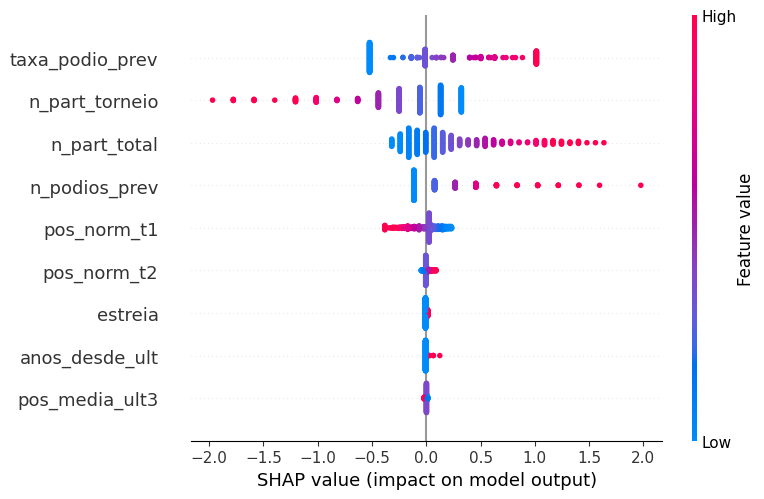

bateria     abominavel
torneio    intermed-pr
ano               2026
podio                0
Name: 4, dtype: object


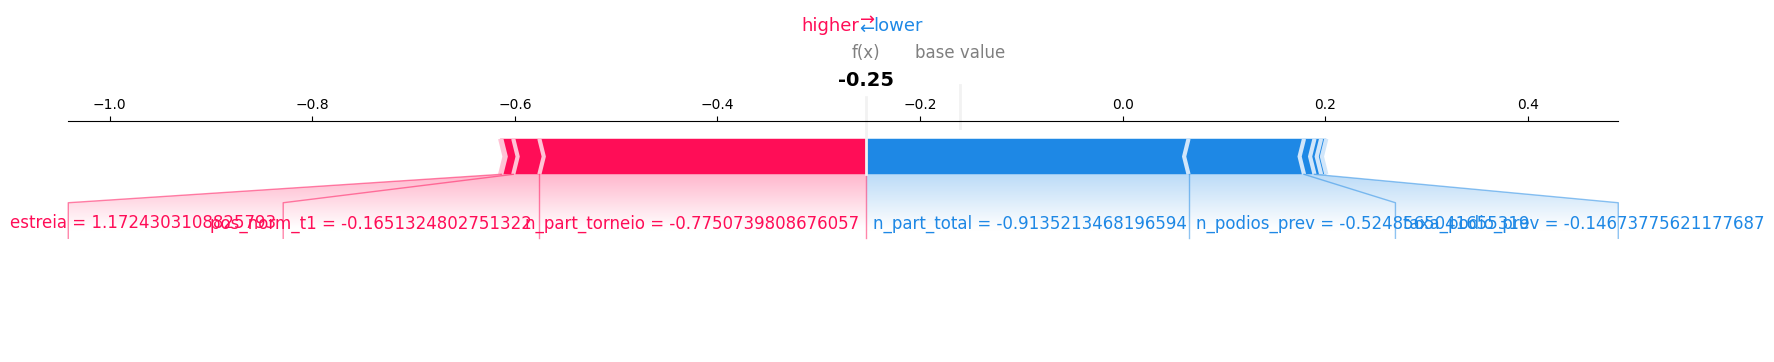

In [ ]:
import shap

pipe = modelos["LogReg"]

# nomes das colunas que sobreviveram ao imputer
mantidas = [f for f, ok in zip(FEATURES, pipe.named_steps["imp"].statistics_ == pipe.named_steps["imp"].statistics_) if ok]
mantidas = list(pipe.named_steps["imp"].get_feature_names_out(FEATURES))

Xtr = pipe[:-1].transform(treino[FEATURES])
Xte = pipe[:-1].transform(teste[FEATURES])

expl = shap.LinearExplainer(pipe.named_steps["clf"], Xtr)
sv = expl.shap_values(Xte)

shap.summary_plot(sv, Xte, feature_names=mantidas)

i = 0
print(teste.iloc[i][["bateria", "torneio", "ano", "podio"]])
shap.force_plot(expl.expected_value, sv[i], Xte[i],
                feature_names=mantidas, matplotlib=True)

In [ ]:
FEATURES = [f for f in FEATURES if f != "pts_norm_media"]

['porcaria']
Histórico dessa bateria nesse torneio:


,ano,posicao,n_part,podio
2000,2019,6.0,19,0
2001,2023,9.0,27,0
2002,2025,3.0,25,1
2003,2026,6.0,24,0


participações da bateria em qualquer torneio: 12


,0
n_part_torneio,4.000000
n_part_total,12.000000
n_podios_prev,1.000000
taxa_podio_prev,0.250000
pos_norm_t1,0.250000
pos_norm_t2,0.120000
pos_media_ult3,0.234444
anos_desde_ult,1.000000
estreia,0.000000


LogReg: P(pódio) = 50.1%
kNN: P(pódio) = 13.3%
taxa base de pódio no treino: 35.3%


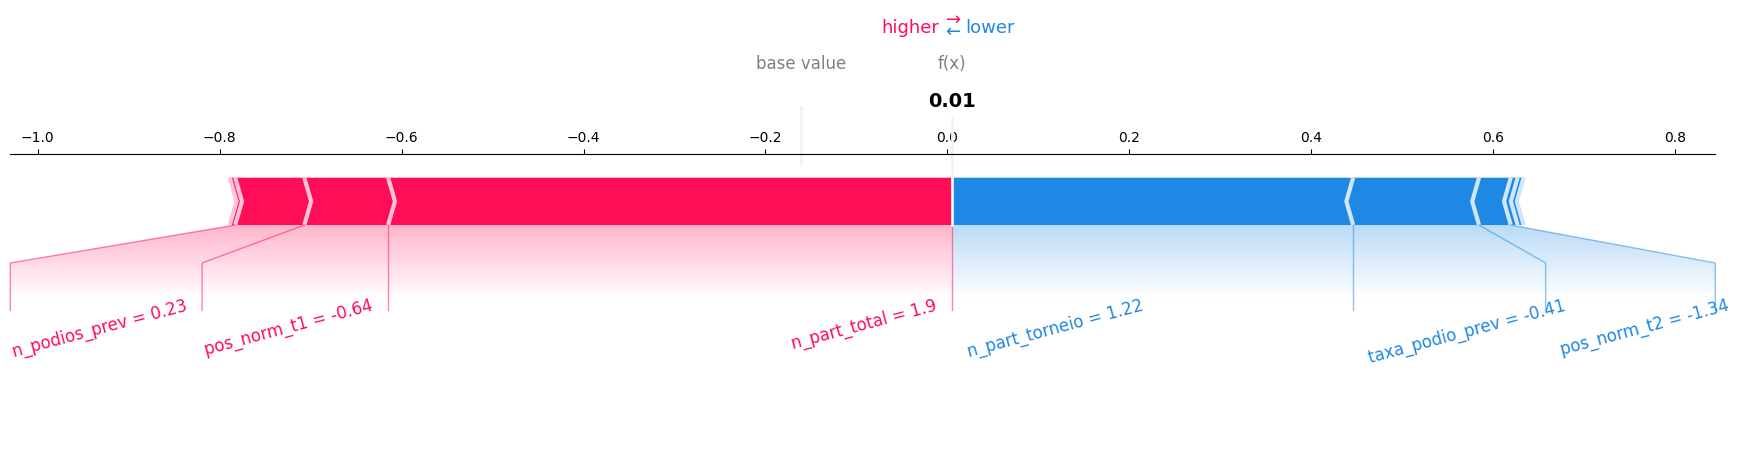

In [ ]:
import shap
import numpy as np

BATERIA, TORNEIO, ANO = "porcaria", "tabu", 2027   # confira os slugs em d["bateria"].unique()
print([b for b in d["bateria"].unique() if "porc" in b])

h = d[(d["bateria"] == BATERIA) & (d["torneio"] == TORNEIO)].sort_values("ano")
print("Histórico dessa bateria nesse torneio:")
display(h[["ano", "posicao", "n_part", "podio"]])
print("participações da bateria em qualquer torneio:", (d["bateria"] == BATERIA).sum())

if (d["bateria"] == BATERIA).sum() == 0:
    raise SystemExit("Bateria não encontrada. Procure o slug: [b for b in d['bateria'].unique() if 'porc' in b]")

# mesmas definições usadas no Feature engineering, mas só com o passado
n = len(h)
linha = {
    "n_part_torneio":  n,
    "n_part_total":    (d["bateria"] == BATERIA).sum(),
    "n_podios_prev":   h["podio"].sum() if n else 0,
    "taxa_podio_prev": h["podio"].sum() / n if n else np.nan,
    "pos_norm_t1":     h["pos_norm"].iloc[-1] if n >= 1 else np.nan,
    "pos_norm_t2":     h["pos_norm"].iloc[-2] if n >= 2 else np.nan,
    "pos_media_ult3":  h["pos_norm"].tail(3).mean() if n else np.nan,
    "anos_desde_ult":  ANO - h["ano"].max() if n else np.nan,
    "estreia":         int(n == 0),
}
X_novo = pd.DataFrame([linha])[FEATURES]      # FEATURES já sem pts_norm_media
display(X_novo.T)

# probabilidade de pódio
for nome, pipe in modelos.items():
    p = pipe.predict_proba(X_novo)[:, 1][0]
    print(f"{nome}: P(pódio) = {p:.1%}")

# referência: taxa média de pódio no treino
print("taxa base de pódio no treino:", f"{treino['podio'].mean():.1%}")

# SHAP local (Regressão Logística)
pipe = modelos["LogReg"]
mantidas = list(pipe.named_steps["imp"].get_feature_names_out(FEATURES))
Xtr = pipe[:-1].transform(treino[FEATURES])
Xn = pipe[:-1].transform(X_novo)
expl = shap.LinearExplainer(pipe.named_steps["clf"], Xtr)
sv = expl.shap_values(Xn)

shap.force_plot(expl.expected_value, sv[0], np.round(Xn[0], 2),
                feature_names=mantidas, matplotlib=True,
                figsize=(22, 4), text_rotation=15)

In [ ]:
tab = pd.DataFrame({"atributo": mantidas, "valor_padronizado": Xn[0].round(2), "shap": sv[0].round(3)})
display(tab.reindex(tab["shap"].abs().sort_values(ascending=False).index))

,atributo,valor_padronizado,shap
1,n_part_total,1.90,0.620
0,n_part_torneio,1.22,-0.441
3,taxa_podio_prev,-0.41,-0.138
4,pos_norm_t1,-0.64,0.092
2,n_podios_prev,0.23,0.076
5,pos_norm_t2,-1.34,-0.035
8,estreia,-0.85,-0.008
7,anos_desde_ult,-0.33,-0.007
6,pos_media_ult3,-0.84,0.006
